# Diabetes status classification — Small neural network

**Dataset:** `diabetes_binary_5050split_health_indicators_BRFSS2015.csv` from DTU Learn. Set `DATA_PATH` below to its local location. Run cells in order. Install dependencies if needed: `pip install numpy pandas scikit-learn matplotlib seaborn` plus `torch captum`.

The label `Diabetes_binary` denotes reported (pre)diabetes **at survey time**. The dataset was deliberately balanced 50/50. A predicted probability is therefore a model score for this sampled population, **not** an individual's future absolute risk. Feature contributions describe the model, not causal effects or medical advice. Keep the held-out test set untouched while choosing settings.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, average_precision_score, RocCurveDisplay,
                             brier_score_loss)
from sklearn.inspection import permutation_importance

DATA_PATH = Path('diabetes_binary_5050split_health_indicators_BRFSS2015.csv')
SEED = 42
if not DATA_PATH.is_file():
    raise FileNotFoundError(f'Set DATA_PATH to the CSV downloaded from DTU Learn: {DATA_PATH.resolve()}')
df = pd.read_csv(DATA_PATH)
target = 'Diabetes_binary'
if target not in df:
    raise KeyError(f'Missing {target}; columns: {df.columns.tolist()}')
if df.columns.duplicated().any():
    raise ValueError('Duplicate column names')
X = df.drop(columns=target).apply(pd.to_numeric, errors='raise')
y = df[target].astype(int)
assert set(y.unique()) == {0, 1}, 'Expected binary label 0/1'
print('Rows, features:', X.shape, '| positive fraction:', round(y.mean(), 3))
print('Missing values:', int(X.isna().sum().sum()))
display(X.head())

# Identical split in both notebooks. Split before fitting any imputation/scaling.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)
features = X.columns.tolist()


Rows, features: (70692, 21) | positive fraction: 0.5
Missing values: 0


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,1.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,0.0,1.0,...,1.0,0.0,3.0,5.0,30.0,0.0,1.0,4.0,6.0,8.0
1,1.0,1.0,1.0,26.0,1.0,1.0,0.0,0.0,1.0,0.0,...,1.0,0.0,3.0,0.0,0.0,0.0,1.0,12.0,6.0,8.0
2,0.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,1.0,1.0,...,1.0,0.0,1.0,0.0,10.0,0.0,1.0,13.0,6.0,8.0
3,1.0,1.0,1.0,28.0,1.0,0.0,0.0,1.0,1.0,1.0,...,1.0,0.0,3.0,0.0,3.0,0.0,1.0,11.0,6.0,8.0
4,0.0,0.0,1.0,29.0,1.0,0.0,0.0,1.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,8.0,5.0,8.0


## Prepare inputs and train

A training-only median imputer and standard scaler prevent leakage. A small network with one hidden layer outputs a logit. BCEWithLogitsLoss handles the sigmoid stably.

Device: cpu | final validation loss: 0.502


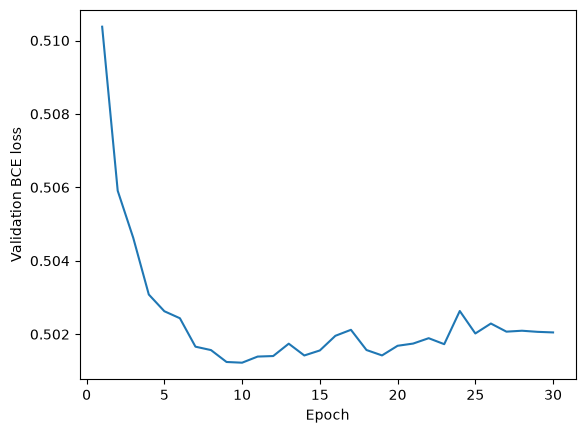

In [7]:
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
preprocess = make_pipeline(SimpleImputer(strategy='median'), StandardScaler())
Z_train = preprocess.fit_transform(X_train).astype('float32')
Z_test = preprocess.transform(X_test).astype('float32')
# Validation comes exclusively from the training portion, with the same seed.
Z_fit, Z_val, y_fit, y_val = train_test_split(
    Z_train, y_train.to_numpy(), test_size=0.20,
    stratify=y_train, random_state=SEED)
loader = DataLoader(TensorDataset(torch.from_numpy(Z_fit),
                                  torch.from_numpy(y_fit.astype('float32'))),
                    batch_size=256, shuffle=True)
net = nn.Sequential(nn.Linear(len(features), 32), nn.ReLU(), nn.Linear(32, 1)).to(device)
optimizer = torch.optim.Adam(net.parameters(), lr=1e-3, weight_decay=1e-4)
loss_fn = nn.BCEWithLogitsLoss()
history = []
for epoch in range(30):
    net.train()
    for xb, yb in loader:
        optimizer.zero_grad()
        loss = loss_fn(net(xb.to(device)).squeeze(1), yb.to(device))
        loss.backward()
        optimizer.step()
    net.eval()
    with torch.no_grad():
        val_logits = net(torch.from_numpy(Z_val).to(device)).squeeze(1)
        val_loss = loss_fn(val_logits, torch.from_numpy(y_val.astype('float32')).to(device)).item()
    history.append(val_loss)
print('Device:', device, '| final validation loss:', round(history[-1], 4))
plt.plot(range(1, len(history)+1), history)
plt.xlabel('Epoch'); plt.ylabel('Validation BCE loss'); plt.show()


## Held-out evaluation

The fixed 30 epochs are an illustrative baseline. Choose any tuning or early stopping using validation data only.

                  precision    recall  f1-score   support

no (pre)diabetes       0.78      0.70      0.74      7070
   (pre)diabetes       0.73      0.80      0.76      7069

        accuracy                           0.75     14139
       macro avg       0.75      0.75      0.75     14139
    weighted avg       0.75      0.75      0.75     14139

ROC AUC: 0.830
Average precision: 0.805
Brier score (balanced sample only): 0.167


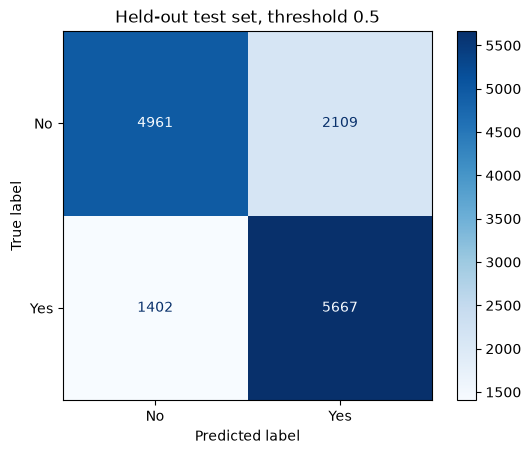

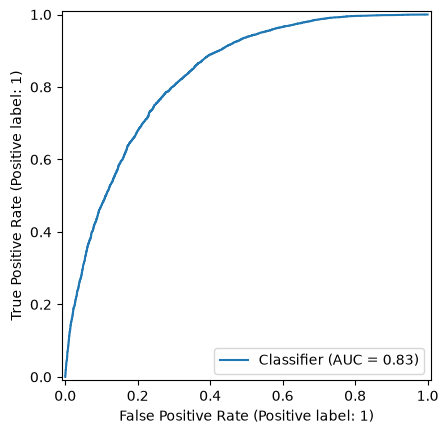

In [8]:
net.eval()
with torch.no_grad():
    probabilities = torch.sigmoid(net(torch.from_numpy(Z_test).to(device))).cpu().numpy().ravel()
def evaluate(y_true, probability, threshold=0.5):
    prediction = (probability >= threshold).astype(int)
    print(classification_report(y_true, prediction, target_names=['no (pre)diabetes', '(pre)diabetes']))
    print(f'ROC AUC: {roc_auc_score(y_true, probability):.3f}')
    print(f'Average precision: {average_precision_score(y_true, probability):.3f}')
    print(f'Brier score (balanced sample only): {brier_score_loss(y_true, probability):.3f}')
    ConfusionMatrixDisplay.from_predictions(y_true, prediction, display_labels=['No', 'Yes'], cmap='Blues')
    plt.title('Held-out test set, threshold 0.5'); plt.show()
    RocCurveDisplay.from_predictions(y_true, probability); plt.show()

evaluate(y_test, probabilities)


## Global explanation: permutation importance

The wrapper applies the training-only preprocessing before calling the network.

In [13]:
from sklearn.base import BaseEstimator, ClassifierMixin

class NetworkClassifier(ClassifierMixin, BaseEstimator):
    def __init__(self):
        self.classes_ = np.array([0, 1])

    def fit(self, X=None, y=None):
        # The network and preprocessing are already trained.
        return self

    def predict_proba(self, X_input):
        z = preprocess.transform(X_input).astype('float32')
        net.eval()
        with torch.no_grad():
            p = torch.sigmoid(
                net(torch.from_numpy(z).to(device))
            ).cpu().numpy().ravel()
        return np.column_stack([1 - p, p])

## Local explanation: Integrated Gradients

Attributions are for the **logit**, relative to a median-feature baseline transformed with the training scaler. Positive values raise the logit relative to that baseline. Correlation, the chosen baseline and model error limit interpretation. These values are not causal intervention effects.

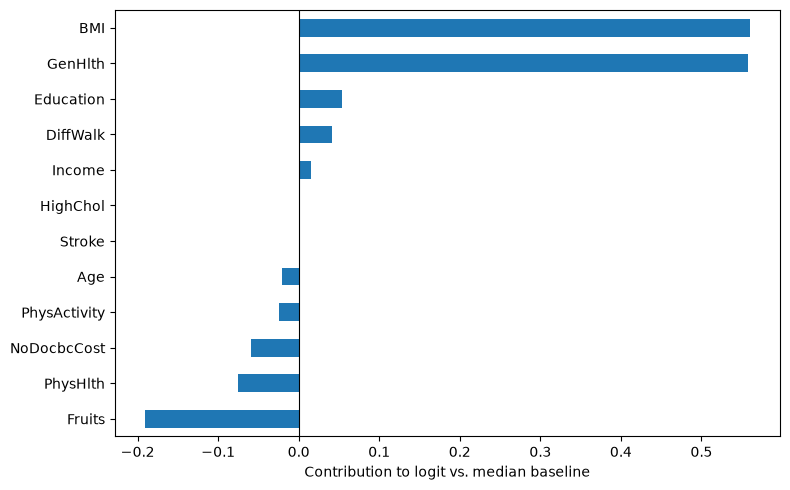

Model score: 0.886
True survey label: 1
IG convergence delta: 0.00203627347946167


In [14]:
from captum.attr import IntegratedGradients

row_position = 0
row = X_test.iloc[[row_position]]
z = torch.from_numpy(preprocess.transform(row).astype('float32')).to(device)
# Training medians correspond approximately to zero after imputation and scaling.
baseline_raw = pd.DataFrame([X_train.median()], columns=features)
baseline = torch.from_numpy(preprocess.transform(baseline_raw).astype('float32')).to(device)
net.eval()
attr, delta = IntegratedGradients(net).attribute(
    z, baselines=baseline, n_steps=100, return_convergence_delta=True)
local = pd.Series(attr.detach().cpu().numpy().ravel(), index=features).sort_values()
pd.concat([local.head(6), local.tail(6)]).plot.barh(figsize=(8, 5))
plt.axvline(0, color='black', lw=0.8)
plt.xlabel('Contribution to logit vs. median baseline'); plt.tight_layout(); plt.show()
print('Model score:', round(model.predict_proba(row)[0, 1], 3))
print('True survey label:', int(y_test.iloc[row_position]))
print('IG convergence delta:', float(delta.detach().cpu().item()))


## Error audit

In [15]:
audit = X_test.copy()
audit['actual'] = y_test
audit['score'] = probabilities
audit['predicted'] = (probabilities >= 0.5).astype(int)
display(audit.loc[(audit.actual == 1) & (audit.predicted == 0)].sort_values('score').head(10))
display(audit.loc[(audit.actual == 0) & (audit.predicted == 1)].sort_values('score', ascending=False).head(10))


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,actual,score,predicted
66055,0.0,0.0,1.0,20.0,0.0,0.0,0.0,1.0,1.0,1.0,...,0.0,0.0,0.0,1.0,2.0,6.0,7.0,1,0.006883,0
51216,0.0,0.0,1.0,24.0,1.0,0.0,0.0,1.0,0.0,1.0,...,5.0,1.0,0.0,0.0,3.0,6.0,5.0,1,0.011584,0
41488,0.0,0.0,1.0,26.0,1.0,0.0,0.0,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,3.0,5.0,6.0,1,0.014418,0
67194,0.0,0.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,1.0,...,20.0,1.0,0.0,1.0,3.0,6.0,8.0,1,0.019461,0
41386,0.0,0.0,1.0,22.0,0.0,0.0,0.0,1.0,1.0,1.0,...,0.0,0.0,0.0,1.0,2.0,5.0,8.0,1,0.020937,0
49746,0.0,0.0,1.0,22.0,0.0,0.0,0.0,1.0,1.0,1.0,...,1.0,0.0,0.0,1.0,6.0,6.0,8.0,1,0.021913,0
50392,0.0,0.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,1.0,...,0.0,0.0,0.0,0.0,2.0,6.0,7.0,1,0.022388,0
38149,0.0,0.0,1.0,23.0,0.0,0.0,0.0,1.0,0.0,1.0,...,0.0,0.0,0.0,1.0,5.0,6.0,8.0,1,0.023131,0
55644,0.0,1.0,1.0,22.0,0.0,0.0,0.0,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,8.0,6.0,7.0,1,0.026414,0
37605,0.0,0.0,1.0,28.0,0.0,0.0,0.0,1.0,1.0,1.0,...,15.0,0.0,0.0,0.0,3.0,6.0,8.0,1,0.027878,0


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,actual,score,predicted
3439,1.0,0.0,1.0,72.0,0.0,1.0,1.0,1.0,1.0,1.0,...,0.0,30.0,1.0,0.0,10.0,5.0,2.0,0,0.968011,1
26200,1.0,1.0,1.0,37.0,0.0,1.0,1.0,1.0,1.0,1.0,...,5.0,5.0,1.0,0.0,5.0,4.0,2.0,0,0.950275,1
19581,1.0,1.0,1.0,42.0,0.0,0.0,1.0,0.0,1.0,1.0,...,0.0,7.0,1.0,0.0,12.0,2.0,3.0,0,0.949297,1
20936,1.0,1.0,1.0,46.0,1.0,0.0,1.0,1.0,1.0,0.0,...,15.0,15.0,1.0,1.0,7.0,4.0,3.0,0,0.945164,1
12226,1.0,1.0,1.0,32.0,0.0,1.0,1.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,13.0,3.0,2.0,0,0.941813,1
781,1.0,1.0,1.0,46.0,1.0,0.0,1.0,0.0,1.0,1.0,...,4.0,10.0,1.0,1.0,9.0,4.0,3.0,0,0.938469,1
30535,1.0,1.0,1.0,45.0,1.0,0.0,0.0,0.0,1.0,1.0,...,30.0,25.0,1.0,0.0,9.0,6.0,5.0,0,0.933067,1
8841,1.0,1.0,1.0,38.0,0.0,1.0,1.0,1.0,1.0,1.0,...,30.0,30.0,1.0,1.0,8.0,6.0,7.0,0,0.932836,1
8479,1.0,1.0,1.0,31.0,1.0,1.0,1.0,1.0,1.0,1.0,...,0.0,0.0,0.0,1.0,12.0,5.0,3.0,0,0.928746,1
7005,1.0,1.0,1.0,43.0,0.0,0.0,1.0,1.0,0.0,1.0,...,0.0,30.0,1.0,1.0,6.0,6.0,1.0,0,0.928424,1


c:\Users\vict7\miniforge3\envs\forklarbar-fixed\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but SimpleImputer was fitted with feature names
  warnings.warn(


Modelscore for (præ)diabetes: 0.886
[('CholCheck=1', 0.25449530788934505), ('BMI > 33.00', 0.19363860228603547), ('3.00 < GenHlth <= 4.00', 0.1841013631507309), ('HvyAlcoholConsump=0', 0.1726028324244363), ('HighBP=1', 0.14350900780702672), ('HeartDiseaseorAttack=0', -0.11990692321870805), ('HighChol=1', 0.10436635271691541), ('Stroke=0', -0.10158036210639121), ('9.00 < Age <= 11.00', 0.07582224782719306), ('Income <= 4.00', 0.05333283624009429)]


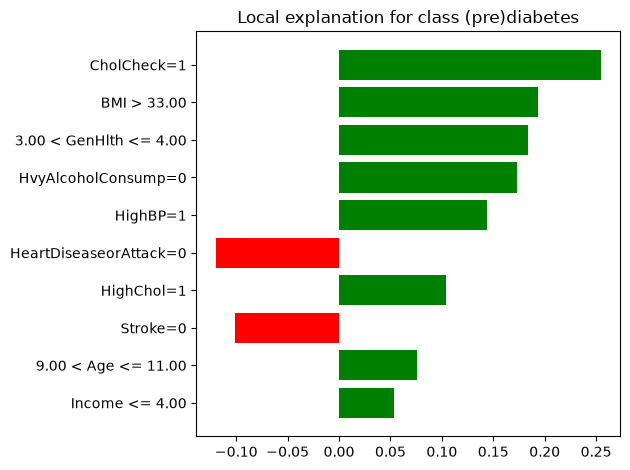

In [16]:
from lime.lime_tabular import LimeTabularExplainer

# Fortæl LIME, hvilke inputvariabler der kun har værdierne 0 og 1
categorical_features = [
    i for i, feature in enumerate(features)
    if X_train[feature].nunique(dropna=True) <= 2
]

lime_explainer = LimeTabularExplainer(
    training_data=X_train.to_numpy(dtype=float),
    feature_names=features,
    class_names=["No (pre)diabetes", "(pre)diabetes"],
    categorical_features=categorical_features,
    mode="classification",
    random_state=SEED
)

# Vælg én person fra testdata
row_position = 0
row = X_test.iloc[row_position]

lime_explanation = lime_explainer.explain_instance(
    data_row=row.to_numpy(dtype=float),
    predict_fn=model.predict_proba,
    labels=(1,),
    num_features=10,
    num_samples=3000
)

# Vis hvilke variabler der påvirker forklaringen for klasse 1
print("Modelscore for (præ)diabetes:",
      round(model.predict_proba(row.to_frame().T)[0, 1], 3))
print(lime_explanation.as_list(label=1))

lime_explanation.as_pyplot_figure(label=1)
plt.tight_layout()
plt.show()

In [19]:
print("LIME local fidelity:", lime_explanation.score)

LIME local fidelity: 0.4788278979349657


In [22]:
import copy
import numpy as np
import pandas as pd
import torch
from IPython.display import display

# Brug din eksisterende LIME-explainer:
base_explainer = lime_explainer  # Ret til lime_explainer, hvis det er navnet

# Samme respondent som tidligere.
# row_position er defineret tidligere i din notebook.
respondent = X_test.iloc[row_position].to_numpy(dtype=float)

N_RUNS = 20
N_SAMPLES = 3000
N_FEATURES = 10  # Samme antal som i din viste LIME-figur
TOP_K = 5
POSITIVE_CLASS = 1

feature_names = X_train.columns.tolist()


# LIME sender rå featureværdier ind.
# Brug præcis samme preprocessing og trænede netværk.
def predict_for_lime(values):
    frame = pd.DataFrame(values, columns=feature_names)
    transformed = preprocess.transform(frame).astype("float32")

    net.eval()
    with torch.no_grad():
        logits = net(
            torch.from_numpy(transformed).to(device)
        ).reshape(-1)

        positive = torch.sigmoid(logits).cpu().numpy()

    return np.column_stack([1 - positive, positive])


model_score = float(
    predict_for_lime(respondent.reshape(1, -1))[0, POSITIVE_CLASS]
)

run_results = []
top_features = []
lime_explanations = {}

for seed in range(N_RUNS):
    # Bevar opsætningen fra den oprindelige forklaring.
    # Kopiering undgår at ændre din eksisterende explainer.
    current_explainer = copy.deepcopy(base_explainer)

    rng = np.random.RandomState(seed)
    current_explainer.random_state = rng

    if getattr(current_explainer, "discretizer", None) is not None:
        current_explainer.discretizer.random_state = rng

    explanation = current_explainer.explain_instance(
        data_row=respondent,
        predict_fn=predict_for_lime,
        labels=(POSITIVE_CLASS,),
        top_labels=None,
        num_features=N_FEATURES,
        num_samples=N_SAMPLES,
    )

    lime_explanations[seed] = explanation

    surrogate_score = float(
        np.asarray(explanation.local_pred).reshape(-1)[0]
    )

    run_results.append({
        "seed": seed,
        "local_fidelity": float(explanation.score),
        "NN_score": model_score,
        "LIME_score": surrogate_score,
        "absolute_local_error": abs(surrogate_score - model_score),
    })

    # Rangér efter størrelsen af bidraget, uanset fortegn.
    weights = explanation.as_map()[POSITIVE_CLASS]
    strongest = sorted(
        weights, key=lambda item: abs(item[1]), reverse=True
    )[:TOP_K]

    for feature_id, weight in strongest:
        top_features.append({
            "seed": seed,
            "feature": feature_names[feature_id],
            "weight": float(weight),
        })

    print(f"Kørsel {seed + 1}/{N_RUNS} færdig")


# 1. Resultater fra alle 20 kørsler
lime_runs = pd.DataFrame(run_results)

print(f"\nRespondentens position i testsættet: {row_position}")
print(f"Respondentens oprindelige indeks: {X_test.index[row_position]}")
print(f"NN-score: {model_score:.4f}")

display(lime_runs.round(4))


# 2. Samlet fidelity og fejl ved selve respondenten
lime_summary = (
    lime_runs[["local_fidelity", "absolute_local_error"]]
    .agg(["mean", "std", "min", "max"])
    .T
)

print("\nOpsummering af de 20 kørsler:")
display(lime_summary.round(4))


# 3. Stabilitet af de fem vigtigste features
top_features = pd.DataFrame(top_features)

feature_stability = (
    top_features.groupby("feature")
    .agg(
        top5_count=("seed", "nunique"),
        positive_count=("weight", lambda s: int((s > 0).sum())),
        negative_count=("weight", lambda s: int((s < 0).sum())),
    )
)

feature_stability["top5_frequency_pct"] = (
    100 * feature_stability["top5_count"] / N_RUNS
)

feature_stability = feature_stability.sort_values(
    ["top5_count", "feature"], ascending=[False, True]
)

print("\nHvor ofte er hver feature blandt de fem vigtigste?")
display(feature_stability.round(1))

Kørsel 1/20 færdig
Kørsel 2/20 færdig
Kørsel 3/20 færdig
Kørsel 4/20 færdig
Kørsel 5/20 færdig
Kørsel 6/20 færdig
Kørsel 7/20 færdig
Kørsel 8/20 færdig
Kørsel 9/20 færdig
Kørsel 10/20 færdig
Kørsel 11/20 færdig
Kørsel 12/20 færdig
Kørsel 13/20 færdig
Kørsel 14/20 færdig
Kørsel 15/20 færdig
Kørsel 16/20 færdig
Kørsel 17/20 færdig
Kørsel 18/20 færdig
Kørsel 19/20 færdig
Kørsel 20/20 færdig

Respondentens position i testsættet: 0
Respondentens oprindelige indeks: 57608
NN-score: 0.8856


,seed,local_fidelity,NN_score,LIME_score,absolute_local_error
0,0,0.4603,0.8856,1.0048,0.1192
1,1,0.4564,0.8856,1.0115,0.1259
2,2,0.4644,0.8856,0.9714,0.0858
3,3,0.4713,0.8856,1.0135,0.1279
4,4,0.4629,0.8856,1.0126,0.1271
5,5,0.4634,0.8856,1.0109,0.1253
6,6,0.4722,0.8856,1.0267,0.1412
7,7,0.4903,0.8856,1.0330,0.1474
8,8,0.4569,0.8856,1.0103,0.1247
9,9,0.4765,0.8856,1.0111,0.1255



Opsummering af de 20 kørsler:


,mean,std,min,max
local_fidelity,0.4656,0.0122,0.4485,0.4903
absolute_local_error,0.1229,0.0141,0.0858,0.1474



Hvor ofte er hver feature blandt de fem vigtigste?


,top5_count,positive_count,negative_count,top5_frequency_pct
feature,,,,
BMI,20,20,0,100.0
CholCheck,20,20,0,100.0
GenHlth,20,20,0,100.0
HvyAlcoholConsump,20,20,0,100.0
HighBP,18,18,0,90.0
HighChol,2,2,0,10.0


c:\Users\vict7\miniforge3\envs\forklarbar-fixed\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but SimpleImputer was fitted with feature names
  warnings.warn(
  0%|          | 0/40 [00:00<?, ?it/s]c:\Users\vict7\miniforge3\envs\forklarbar-fixed\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but SimpleImputer was fitted with feature names
  warnings.warn(
c:\Users\vict7\miniforge3\envs\forklarbar-fixed\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but SimpleImputer was fitted with feature names
  warnings.warn(
c:\Users\vict7\miniforge3\envs\forklarbar-fixed\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but SimpleImputer was fitted with feature names
  warnings.warn(
c:\Users\vict7\miniforge3\envs\forklarbar-fixed\Lib\site-packages\sklearn\utils\validation.py:2830: Us

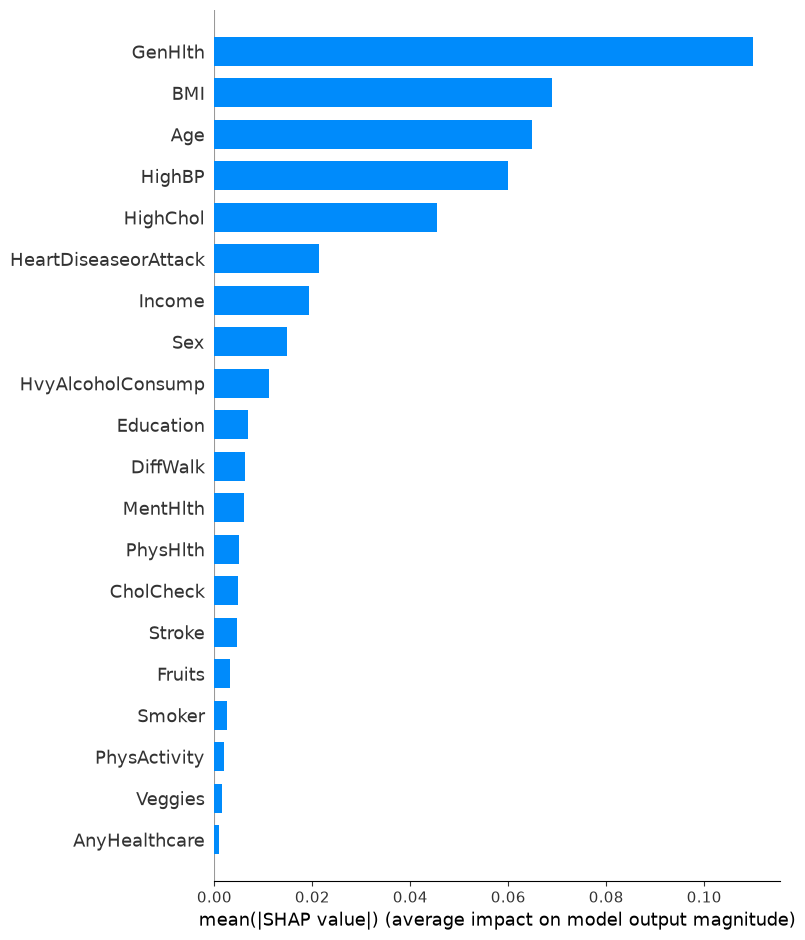

In [17]:
import shap

# Et lille udsnit af træningsdata bruges som sammenligningsgrundlag
background = X_train.sample(
    n=min(50, len(X_train)),
    random_state=SEED
)

# Forklar op til 40 testpersoner
X_shap = X_test.sample(
    n=min(40, len(X_test)),
    random_state=SEED
)

shap_explainer = shap.KernelExplainer(
    model.predict_proba,
    background
)

shap_values = shap_explainer.shap_values(
    X_shap,
    nsamples=200
)

# Udtræk SHAP-værdier for klasse 1: (præ)diabetes
# SHAP-versioner kan returnere værdierne i lidt forskellige formater.
if isinstance(shap_values, list):
    shap_positive = shap_values[1]
else:
    shap_values = np.asarray(shap_values)
    shap_positive = shap_values[:, :, 1] if shap_values.ndim == 3 else shap_values

# Samlet oversigt: hvilke variabler betyder mest på tværs af personerne?
shap.summary_plot(
    shap_positive,
    X_shap,
    feature_names=features,
    plot_type="bar"
)

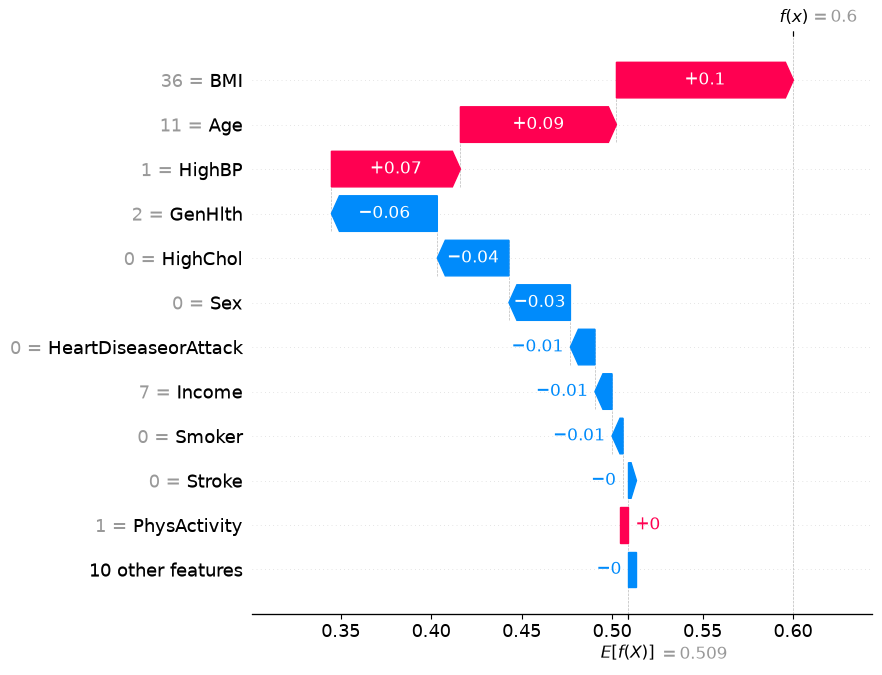

In [18]:
base_value = shap_explainer.expected_value
if np.ndim(base_value) > 0:
    base_value = base_value[1]

local_shap = shap.Explanation(
    values=shap_positive[0],
    base_values=base_value,
    data=X_shap.iloc[0].to_numpy(),
    feature_names=features
)

shap.plots.waterfall(local_shap, max_display=12)